In [1]:
%matplotlib inline
from matplotlib import pyplot as plt
import numpy as np

In [26]:
# each point is length, width, type (0, 1)

#data = [[3,   1.5, 1],
#       [2,   1,   0],
#        [4,   1.5, 1],
#        [3,   1,   0],
#        [3.5, .5,  1],
#        [2,   .5,  0],
#        [5.5,  1,  1],
#        [1,    1,  0]]

#mystery_flower = [3.5, 1]
data = [
    ["I love this product, it is amazing", 1],
    ["This is the worst experience ever", 0],
    ["Absolutely wonderful and highly recommended", 1],
    ["Terrible service and waste of money", 0],
    ["Really great quality and fast shipping", 1],
    ["Bad quality, do not buy this", 0],
    ["I am very happy with my purchase", 1],
    ["Horrible, completely broken on arrival", 0]
]

mystery_flower = "This is a fantastic and beautiful item"

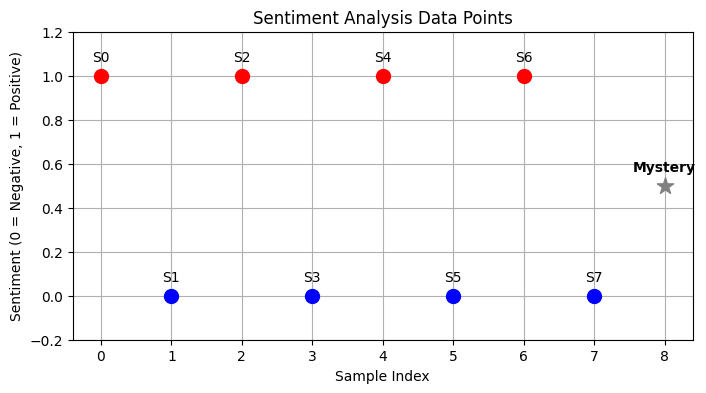

In [28]:
# scatter plot them using indices for x-axis and labels for y-axis
def vis_data():
    plt.figure(figsize=(8, 4))
    plt.grid(True)

    # Plot training data
    for i in range(len(data)):
        c = 'r' if data[i][1] == 1 else 'b'
        # Plot index on X, label (0 or 1) on Y
        plt.scatter(i, data[i][1], c=c, s=100, zorder=3)
        plt.text(i, data[i][1] + 0.05, f"S{i}", ha='center', va='bottom')

    # Plot the mystery statement at a new index
    plt.scatter(len(data), 0.5, c='gray', s=150, marker='*', label='Mystery text (unknown)', zorder=4)
    plt.text(len(data), 0.5 + 0.05, "Mystery", ha='center', va='bottom', weight='bold')

    plt.xlabel("Sample Index")
    plt.ylabel("Sentiment (0 = Negative, 1 = Positive)")
    plt.ylim(-0.2, 1.2)
    plt.title("Sentiment Analysis Data Points")
    plt.show()

vis_data()

In [29]:
# network

#       o  flower type
#      / \  w1, w2, b
#     o   o  length, width

In [30]:
# activation function

def sigmoid(x):
    return 1/(1+np.exp(-x))

def sigmoid_p(x):
    return sigmoid(x) * (1-sigmoid(x))

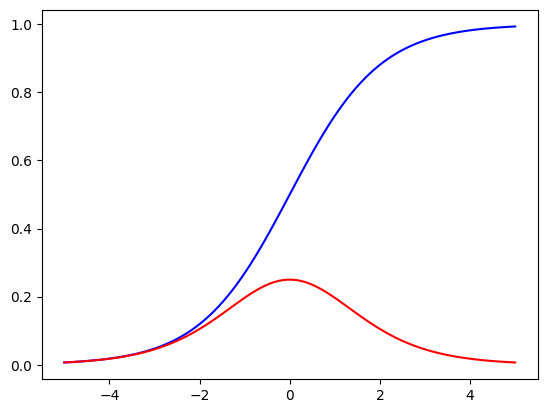

In [31]:
X = np.linspace(-5, 5, 100)

plt.plot(X, sigmoid(X), c="b") # sigmoid in blue
fig = plt.plot(X, sigmoid_p(X), c="r") # sigmoid_p in red

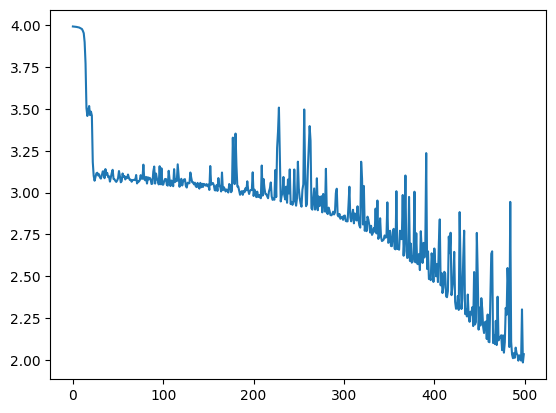

In [33]:
# train

def train():
    # random init of weights
    w1 = np.random.randn()
    w2 = np.random.randn()
    b = np.random.randn()

    iterations = 50000
    learning_rate = 0.001
    costs = [] # keep costs during training, see if they go down

    for i in range(iterations):
        # get a random point
        ri = np.random.randint(len(data))
        point = data[ri]

        # Convert text to numeric features: [char_count, word_count]
        text = point[0]
        x1 = len(text)
        x2 = len(text.split())
        target = point[1]

        z = x1 * w1 + x2 * w2 + b
        pred = sigmoid(z) # networks prediction

        # cost for current random point
        cost = np.square(pred - target)

        # print the cost over all data points every 1k iters
        if i % 100 == 0:
            c = 0
            for j in range(len(data)):
                p = data[j]
                p_x1 = len(p[0])
                p_x2 = len(p[0].split())
                p_pred = sigmoid(w1 * p_x1 + w2 * p_x2 + b)
                c += np.square(p_pred - p[1])
            costs.append(c)

        dcost_dpred = 2 * (pred - target)
        dpred_dz = sigmoid_p(z)

        dz_dw1 = x1
        dz_dw2 = x2
        dz_db = 1

        dcost_dz = dcost_dpred * dpred_dz

        dcost_dw1 = dcost_dz * dz_dw1
        dcost_dw2 = dcost_dz * dz_dw2
        dcost_db = dcost_dz * dz_db

        w1 = w1 - learning_rate * dcost_dw1
        w2 = w2 - learning_rate * dcost_dw2
        b = b - learning_rate * dcost_db

    return costs, w1, w2, b

costs, w1, w2, b = train()

fig = plt.plot(costs)

In [36]:
# predict what the mystery text sentiment is!

# Convert text to numeric features: [char_count, word_count]
x1 = len(mystery_flower)
x2 = len(mystery_flower.split())

z = w1 * x1 + w2 * x2 + b
pred = sigmoid(z)

print(f"Sentence: '{mystery_flower}'")
print(f"Prediction: {pred:.4f}")
print("Close to 0 -> Negative sentiment, close to 1 -> Positive sentiment")

Sentence: 'This is a fantastic and beautiful item'
Prediction: 0.7241
Close to 0 -> Negative sentiment, close to 1 -> Positive sentiment


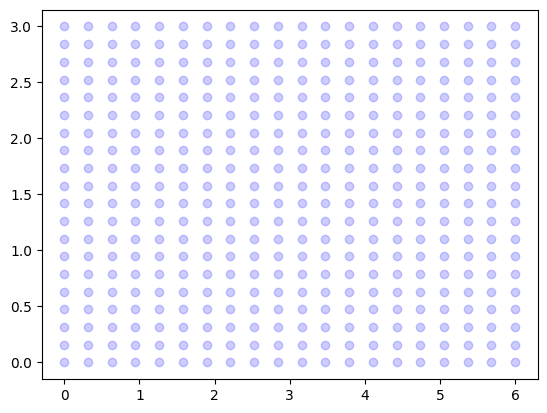

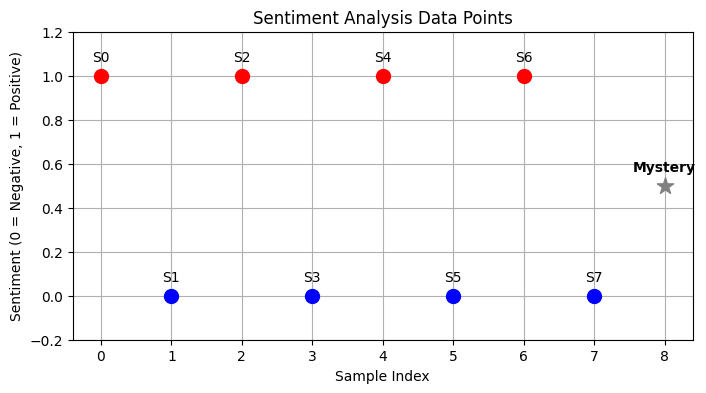

In [37]:
# check out the networks predictions in the x,y plane
for x in np.linspace(0, 6, 20):
    for y in np.linspace(0, 3, 20):
        pred = sigmoid(w1 * x + w2 * y + b)
        c = 'b'
        if pred > .5:
            c = 'r'
        plt.scatter([x],[y],c=c, alpha=.2)

# plot points over network predictions
# you should see a split, with half the predictions blue
# and the other half red.. nicely predicting each data point!
vis_data()